# MIS 205: INTRODUCTION TO PROGRAMMING

---

### Group Information

| Member Name | Student ID |
| :--- | :--- |
| Shahoriar Hossen Siam | ID-131-20-081 |
| M | ID-131-20-081 |
| M | ID-131-20-081 |
| M | ID-131-20-081 |
| M | ID-131-20-081 |

---

### Selected Industry & Organisation

* **Assigned Industry:**
* **Selected Organisation:** *
* **Identified Problem:**

### YouTube API Data Collection Setup

To fetch data from the YouTube Data API, we first obtained a Google Developer API key. Added it securely in Colab's secret manager under the key name `YOUTUBE_API_KEY`.

In [ ]:
import os
import pandas as pd
import json
import re
from googleapiclient.discovery import build
from dotenv import load_dotenv
# from google.colab import userdata

load_dotenv()


# Retrieve API key (with fallback to Colab secrets if run on Colab)
try:
    from google.colab import userdata
    api_key = userdata.get('YOUTUBE_API_KEY')
except Exception:
    api_key = os.getenv('YOUTUBE_API_KEY')


youtube = build('youtube', 'v3', developerKey=api_key)

organisation_query = "Airbnb vs Hotel"
print(f"API initialized. Search query set to: '{organisation_query}'")

API initialized. Search query set to: 'Airbnb'


### Fetching the Data
We will perform a search query to fetch videos related to our organisation, retrieve their statistics (Views, Likes, Comments).

In [48]:
# for cleaning shorts
def parse_duration_seconds(duration_str):
    """Parses ISO 8601 duration (e.g. 'PT5M30S', 'PT45S') to total seconds."""
    match = re.match(r'PT(?:(\d+)H)?(?:(\d+)M)?(?:(\d+)S)?', duration_str)
    if not match:
        return 0
    hours = int(match.group(1) or 0)
    minutes = int(match.group(2) or 0)
    seconds = int(match.group(3) or 0)
    return hours * 3600 + minutes * 60 + seconds






def fetch_video_data(query, max_results=50):
    search_response = youtube.search().list(
        q=query,
        part='id,snippet',
        type='video',
        maxResults=max_results
    ).execute()

    video_ids = [item['id']['videoId'] for item in search_response['items']]

    stats_response = youtube.videos().list(
        part='statistics,snippet,contentDetails',
        id=','.join(video_ids)
    ).execute()


    data = []
    for item in stats_response['items']:

        duration_iso = item.get('contentDetails', {}).get('duration', '')
        duration_sec = parse_duration_seconds(duration_iso)
        # Skip videos under 60 seconds (Shorts)
        if duration_sec <= 60:
            continue


        video_id = item['id']
        title = item['snippet']['title']
        channel_name = item['snippet']['channelTitle']

        # Safely extract metrics (default to 0 if missing/disabled)
        views = int(item['statistics'].get('viewCount', 0))
        likes = int(item['statistics'].get('likeCount', 0))
        comments = int(item['statistics'].get('commentCount', 0))

        data.append({
            'Video ID': video_id,
            'Video Title': title,
            'Channel Name': channel_name,
            'Views': views,
            'Likes': likes,
            'Comments': comments
        })

    df = pd.DataFrame(data)
    return df

df = fetch_video_data(organisation_query)
df.head(5)

,Video ID,Video Title,Channel Name,Views,Likes,Comments
0,Q3jXWW3nMxY,Airbnb introduces new cleaning rules to lessen...,NBC News,75690,455,277
1,9ZXzsjeRtdk,I Tried Every Airbnb Category,Ryan Trahan,28927035,449310,17974
2,Ax-dILXMvfA,Airbnb tour after a guest checkout #airbnb #ai...,Preksha Chand,228420,2597,84
3,wmpTu8sTImQ,Airbnb Changes Leaves Hosts Angry,penguinz0,2155163,42016,5777
4,xyIF9hoNGqU,I Stayed in Every State's Top Ranked Airbnb,Ryan Trahan,21850130,159924,6865


### Data Analysis



#### Calculations

In [46]:
# Total Views
print("Total Views: ", df['Views'].sum())

# Total Likes
print("Total Likes: ", df['Likes'].sum())

# Total Comments
print("Total Comments: ", df['Comments'].sum())

Total Views:  182189520
Total Likes:  2529808
Total Comments:  110747


#### Finds

In [64]:
print("Most viewed video:")
print(df.loc[df['Views'].idxmax()])

print("-"*43)

print("Most Liked video:")
print(df.loc[df['Likes'].idxmax()])

print("-"*43)

print("Top 5 videos by views:")
print(df.sort_values("Views", ascending=False).head(5))


Most viewed video:
Video ID                       Dcp02c9LLEw
Video Title     I Stayed in “OMG!” Airbnbs
Channel Name                   Ryan Trahan
Views                             41261239
Likes                               610212
Comments                             33528
Name: 10, dtype: object
-------------------------------------------
Most Liked video:
Video ID                       Dcp02c9LLEw
Video Title     I Stayed in “OMG!” Airbnbs
Channel Name                   Ryan Trahan
Views                             41261239
Likes                               610212
Comments                             33528
Name: 10, dtype: object
-------------------------------------------
Top 5 videos by views:
       Video ID                                        Video Title  \
10  Dcp02c9LLEw                         I Stayed in “OMG!” Airbnbs   
32  hQfESv-zDD0          I Stayed in World’s MOST EXPENSIVE Airbnb   
1   9ZXzsjeRtdk                      I Tried Every Airbnb Category   
4   xyIF

### Visualizations

#### Trend Analysis: Views & Engagement by Year (2016–2026)

To see how interest in Airbnb has changed over time, we collect the **top 20 most-viewed videos published in each year from 2016 to 2026** (Shorts under 60 seconds are filtered out, matching the cleaning rule used earlier). For each video we record views, likes, comments and publish date, and derive two extra fields:

* **Engagement Rate (%)** = `(Likes + Comments) / Views × 100` — how much interaction a view produces, independent of the video's size.
* **Views per Day** = `Views / days since publish` — normalises for the fact that older videos have had more time to accumulate views.

Two caveats: **(1)** 2026 is a partial year (data collected in October 2026), so its values are not directly comparable with full years. **(2)** Because each year's sample is chosen by *cumulative* view count, older videos are favoured by having had more time to collect views; the views-per-day chart mitigates this, but does not fully remove the selection bias. The raw data is cached to `youtube_trends_2016_2026.csv` so the notebook does not re-spend API quota on every run.

In [65]:
import matplotlib.pyplot as plt
import numpy as np

# Collect 20 videos per year, 2016-2026
TREND_QUERY = "Airbnb"
YEARS = range(2016, 2027)
PER_YEAR = 20
CACHE_FILE = "youtube_trends_2016_2026.csv"


def fetch_videos_for_year(year, query=TREND_QUERY, per_year=PER_YEAR, pool=50):
    """Top `per_year` non-Shorts videos published in `year`, with statistics."""
    search = youtube.search().list(
        q=query,
        part="id",
        type="video",
        order="viewCount",          # top videos of that year, not just recent ones
        maxResults=pool,
        publishedAfter=f"{year}-01-01T00:00:00Z",
        publishedBefore=f"{year}-12-31T23:59:59Z",
    ).execute()

    ids = [item["id"].get("videoId") for item in search.get("items", [])]
    ids = [vid for vid in ids if vid]
    if not ids:
        return pd.DataFrame()

    stats = youtube.videos().list(
        part="statistics,snippet,contentDetails",
        id=",".join(ids),
    ).execute()

    rows = []
    for item in stats.get("items", []):
        duration = parse_duration_seconds(item.get("contentDetails", {}).get("duration", ""))
        if duration <= 60:          # skip Shorts
            continue

        st = item.get("statistics", {})
        views = int(st.get("viewCount", 0) or 0)
        likes = int(st.get("likeCount", 0) or 0)
        comments = int(st.get("commentCount", 0) or 0)
        if views == 0:
            continue

        published = pd.to_datetime(item["snippet"]["publishedAt"]).tz_localize(None)
        age_days = max((pd.Timestamp.now() - published).days, 1)

        rows.append({
            "Year": year,
            "Video ID": item["id"],
            "Video Title": item["snippet"]["title"],
            "Channel Name": item["snippet"]["channelTitle"],
            "Published": published,
            "Duration (s)": duration,
            "Views": views,
            "Likes": likes,
            "Comments": comments,
            "Engagement Rate (%)": (likes + comments) / views * 100,
            "Views per Day": views / age_days,
        })
        if len(rows) == per_year:
            break

    return pd.DataFrame(rows)


if os.path.exists(CACHE_FILE):
    trend_df = pd.read_csv(CACHE_FILE, parse_dates=["Published"])
    print(f"Loaded {len(trend_df)} videos from cache: {CACHE_FILE}")
else:
    frames = []
    for year in YEARS:
        part = fetch_videos_for_year(year)
        frames.append(part)
        print(f"{year}: {len(part)} videos")
    trend_df = pd.concat(frames, ignore_index=True)
    trend_df.to_csv(CACHE_FILE, index=False)
    print(f"\nSaved {len(trend_df)} videos to {CACHE_FILE}")

print("\nVideos per year:")
print(trend_df["Year"].value_counts().sort_index().to_string())
trend_df.head()

Loaded 220 videos from cache: youtube_trends_2016_2026.csv

Videos per year:
Year
2016    20
2017    20
2018    20
2019    20
2020    20
2021    20
2022    20
2023    20
2024    20
2025    20
2026    20


,Year,Video ID,Video Title,Channel Name,Published,Duration (s),Views,Likes,Comments,Engagement Rate (%),Views per Day
0,2016,oGLe0Wgfbyk,Why Your Airbnb May Be ILLEGAL | Adam Ruins Ev...,Dropout,2016-10-05 16:30:00,352,8017239,125747,5112,1.632220,2183.938709
1,2016,OXVRB_u9Y7M,Community Commitment | Airbnb,Airbnb,2016-12-13 20:26:09,75,2314857,397,32,0.018532,642.658801
2,2016,ZSIhEbD6hpQ,最高のLA旅行！Airbnbで知らない人の家に泊まってみた☆ 〔#496〕,バイリンガール英会話 | Bilingirl Chika,2016-12-14 08:37:38,812,1236263,22858,706,1.906067,343.311025
3,2016,m3ZVWt38nC4,Why Airbnb Is Terrible - Cracked Explains,Cracked,2016-08-02 11:30:00,1037,1189764,19518,2848,1.879869,318.544578
4,2016,n0eTLdQ1cQc,Adam Ruins Everything - Why Your Airbnb May Be...,truTV,2016-10-08 13:58:01,343,778162,8073,461,1.096687,212.148855


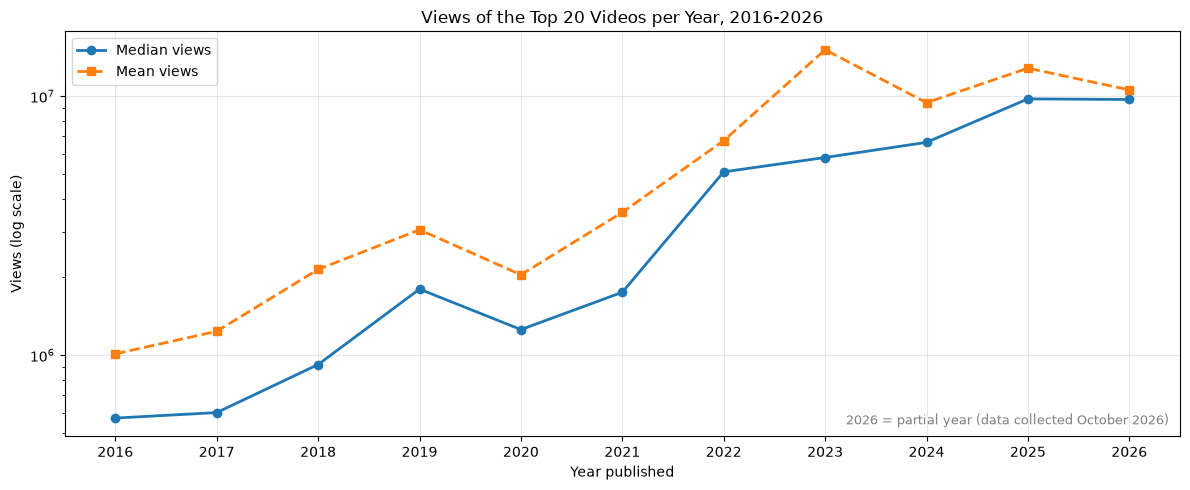

In [66]:
# Chart 1: how big are the most-viewed videos each year?
yearly = trend_df.groupby("Year").agg(
    median_views=("Views", "median"),
    mean_views=("Views", "mean"),
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(yearly.index, yearly["median_views"], marker="o", lw=2, label="Median views")
ax.plot(yearly.index, yearly["mean_views"], marker="s", ls="--", lw=2, label="Mean views")

ax.set_yscale("log")            # views span several orders of magnitude
ax.set_xticks(yearly.index)
ax.set_xlabel("Year published")
ax.set_ylabel("Views (log scale)")
ax.set_title("Views of the Top 20 Videos per Year, 2016-2026")
ax.grid(alpha=0.3)
ax.legend()
ax.text(0.99, 0.03, "2026 = partial year (data collected October 2026)",
        transform=ax.transAxes, ha="right", color="grey", fontsize=9)
plt.tight_layout()
plt.show()

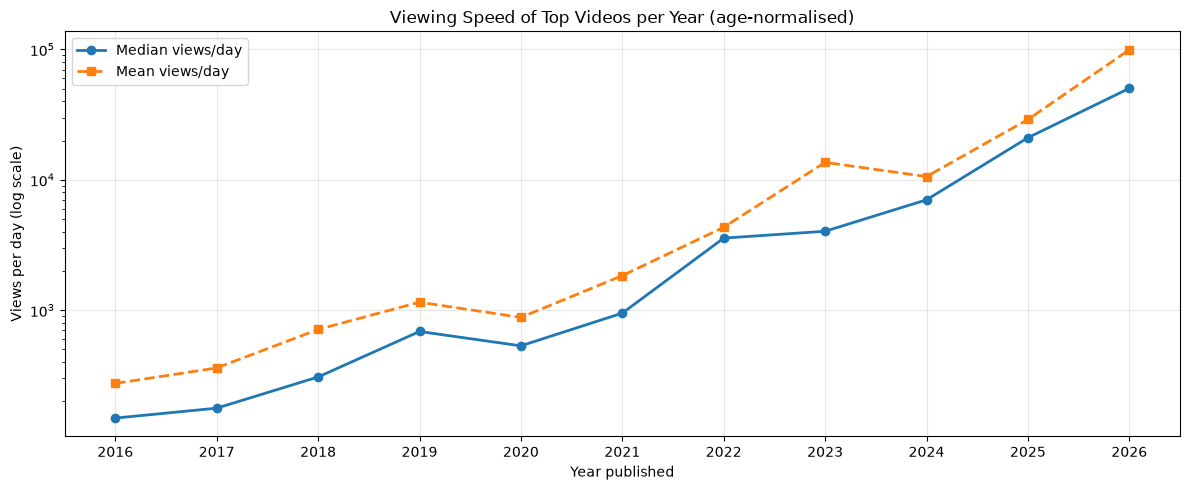

In [67]:
# Chart 2: fairer view comparison - views earned per day since publishing
daily = trend_df.groupby("Year").agg(
    median_per_day=("Views per Day", "median"),
    mean_per_day=("Views per Day", "mean"),
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily.index, daily["median_per_day"], marker="o", lw=2, color="#1f77b4",
        label="Median views/day")
ax.plot(daily.index, daily["mean_per_day"], marker="s", ls="--", lw=2, color="#ff7f0e",
        label="Mean views/day")

ax.set_yscale("log")
ax.set_xticks(daily.index)
ax.set_xlabel("Year published")
ax.set_ylabel("Views per day (log scale)")
ax.set_title("Viewing Speed of Top Videos per Year (age-normalised)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

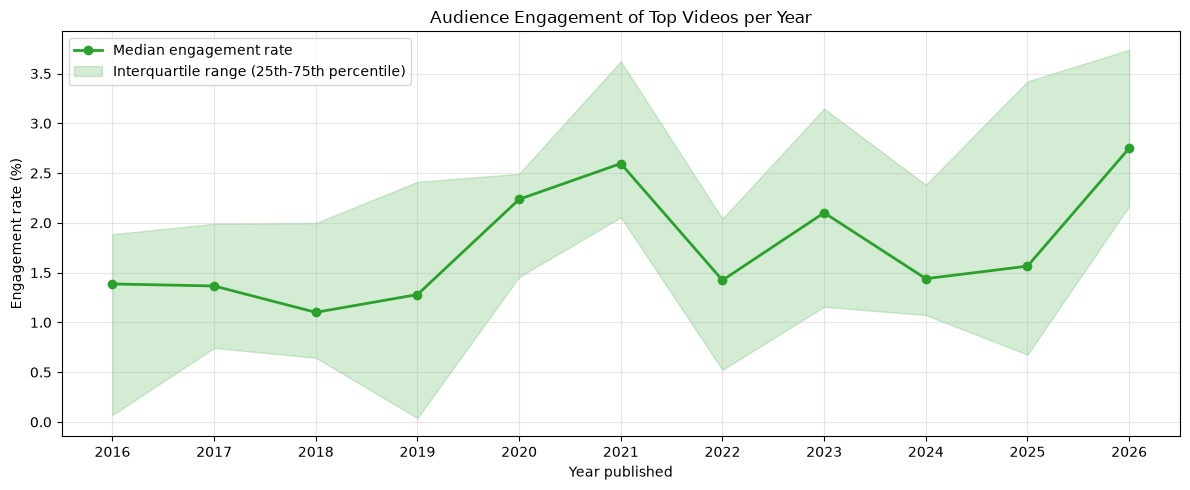

In [68]:
# Chart 3: engagement rate over time (median with interquartile range)
eng = trend_df.groupby("Year")["Engagement Rate (%)"]
median_eng = eng.median()
q1, q3 = eng.quantile(0.25), eng.quantile(0.75)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(median_eng.index, median_eng.values, marker="o", lw=2, color="#2ca02c",
        label="Median engagement rate")
ax.fill_between(q1.index, q1.values, q3.values, alpha=0.2, color="#2ca02c",
                label="Interquartile range (25th-75th percentile)")

ax.set_xticks(median_eng.index)
ax.set_xlabel("Year published")
ax.set_ylabel("Engagement rate (%)")
ax.set_title("Audience Engagement of Top Videos per Year")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

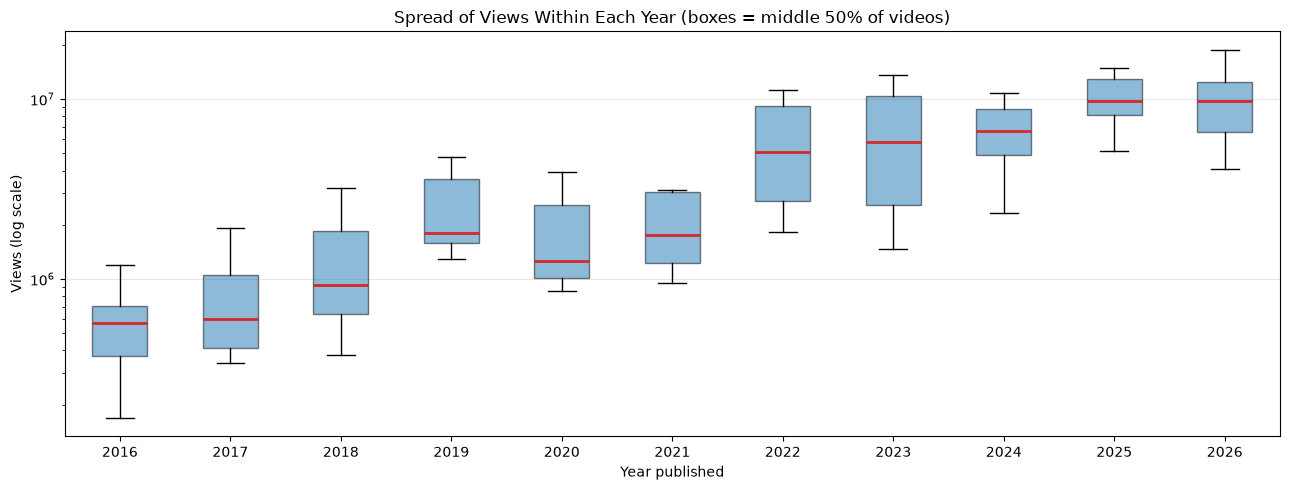

In [69]:
# Chart 4: distribution of views within each year (box plot)
fig, ax = plt.subplots(figsize=(13, 5))
data = [trend_df.loc[trend_df["Year"] == y, "Views"] for y in sorted(trend_df["Year"].unique())]
years = sorted(trend_df["Year"].unique())

bp = ax.boxplot(data, showfliers=False, patch_artist=True)
ax.set_xticks(range(1, len(years) + 1))
ax.set_xticklabels(years)
for box in bp["boxes"]:
    box.set(facecolor="#1f77b4", alpha=0.5)
for median in bp["medians"]:
    median.set(color="#d62728", linewidth=2)

ax.set_yscale("log")
ax.set_xlabel("Year published")
ax.set_ylabel("Views (log scale)")
ax.set_title("Spread of Views Within Each Year (boxes = middle 50% of videos)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

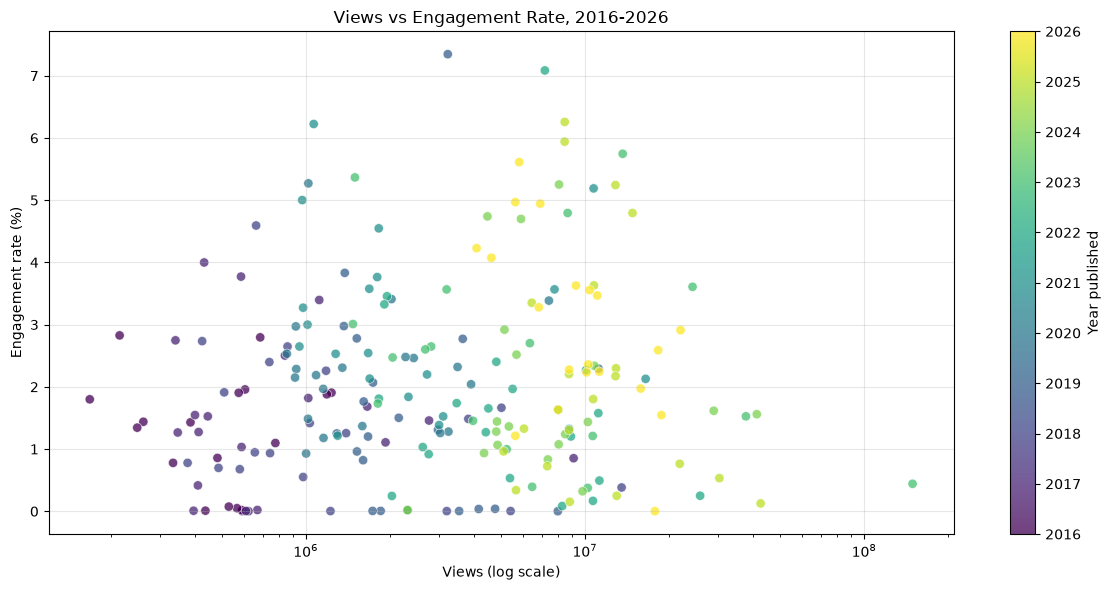

Correlation between views and engagement rate: -0.060


In [70]:
# Chart 5: do bigger videos engage better? (one dot per video, coloured by year)
fig, ax = plt.subplots(figsize=(12, 6))
sc = ax.scatter(
    trend_df["Views"],
    trend_df["Engagement Rate (%)"],
    c=trend_df["Year"],
    cmap="viridis",
    alpha=0.75,
    edgecolor="white",
    linewidth=0.5,
    s=45,
)

ax.set_xscale("log")
ax.set_xlabel("Views (log scale)")
ax.set_ylabel("Engagement rate (%)")
ax.set_title("Views vs Engagement Rate, 2016-2026")
ax.grid(alpha=0.3)
cbar = fig.colorbar(sc, ax=ax, ticks=sorted(trend_df["Year"].unique()))
cbar.set_label("Year published")
plt.tight_layout()
plt.show()

corr = trend_df["Views"].corr(trend_df["Engagement Rate (%)"])
print(f"Correlation between views and engagement rate: {corr:.3f}")

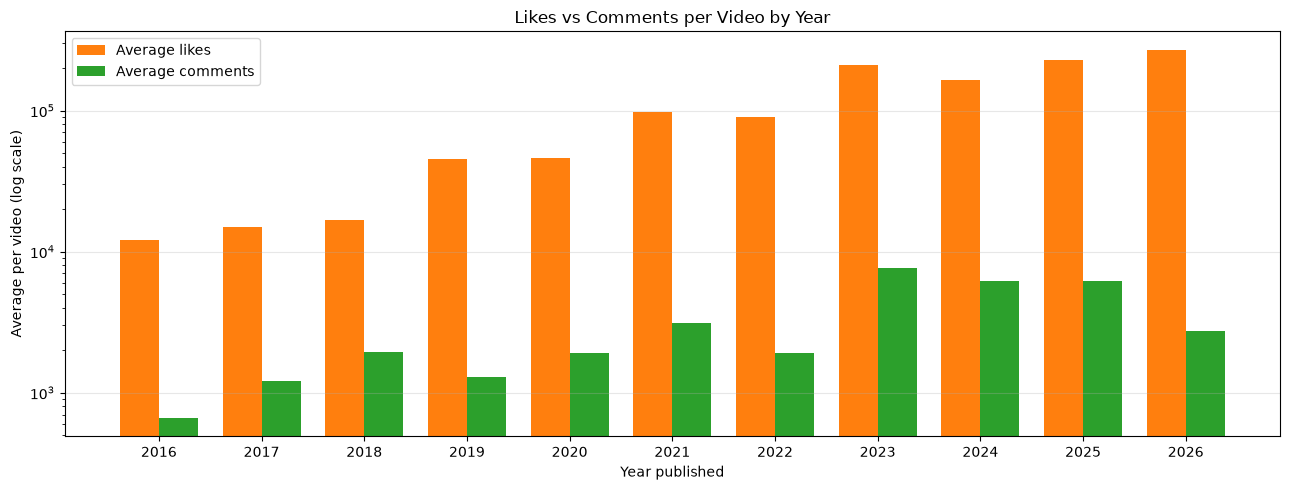

In [71]:
# Chart 6: average likes and comments per video, by year
avg = trend_df.groupby("Year")[["Likes", "Comments"]].mean()
years = avg.index.values
x = np.arange(len(years))
width = 0.38

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - width / 2, avg["Likes"], width, label="Average likes", color="#ff7f0e")
ax.bar(x + width / 2, avg["Comments"], width, label="Average comments", color="#2ca02c")

ax.set_yscale("log")            # comments are far smaller than likes
ax.set_xticks(x)
ax.set_xticklabels(years)
ax.set_xlabel("Year published")
ax.set_ylabel("Average per video (log scale)")
ax.set_title("Likes vs Comments per Video by Year")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

#### Top Videos: Views vs Likes vs Comments

/tmp/ipykernel_316531/1615449669.py:26: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/calibur/codes/205-project/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


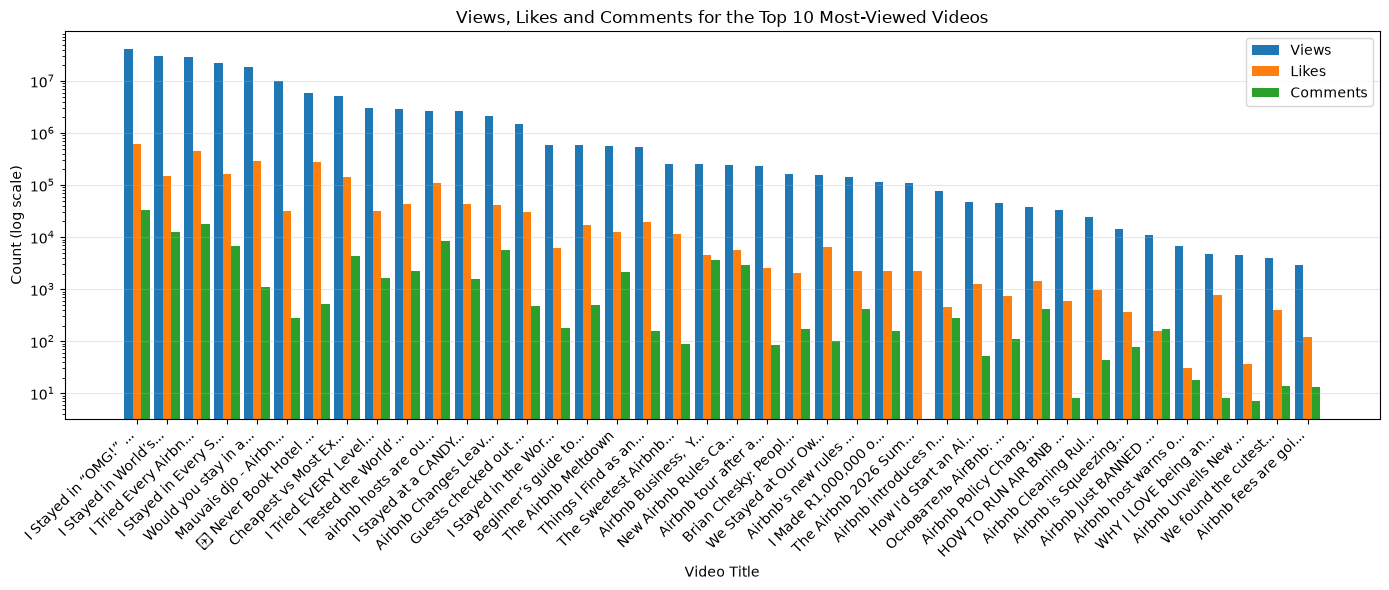

In [41]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = df.sort_values("Views", ascending=False).head(50).copy()
plot_df["Short Title"] = plot_df["Video Title"].apply(
    lambda t: t if len(t) <= 22 else t[:19] + "..."
)

x = np.arange(len(plot_df))   # one x position per video
width = 0.28                  # width of each of the 3 bars

fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(x - width, plot_df["Views"],    width, label="Views",    color="#1f77b4")
ax.bar(x,         plot_df["Likes"],    width, label="Likes",    color="#ff7f0e")
ax.bar(x + width, plot_df["Comments"], width, label="Comments", color="#2ca02c")

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Short Title"], rotation=45, ha="right")
ax.set_xlabel("Video Title")
ax.set_ylabel("Count (log scale)")
ax.set_title(f"Views, Likes and Comments for the Top {len(plot_df)} Most-Viewed Videos")
ax.set_yscale("log")   # log scale so Likes/Comments stay readable next to Views
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


### Findings